# OpenPOM — 5-Fold Cross Validation

# Imports & Paths

In [7]:
import ast, os, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import deepchem as dc
from deepchem.data import NumpyDataset
from openpom.feat.graph_featurizer import GraphFeaturizer, GraphConvConstants
from openpom.utils.data_utils import get_class_imbalance_ratio
from openpom.models.mpnn_pom import MPNNPOMModel
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

warnings.simplefilter("ignore", category=FutureWarning)

BASE_DIR = Path(__file__).resolve().parent if "__file__" in dir() else Path.cwd()
DATA_DIR = BASE_DIR / "data"

# Load TASKS from dataset

In [8]:
_lists = (
    pd.read_csv(DATA_DIR / "Total_dataset_All_Food.csv", sep=";", header=0)["Labels"]
    .apply(ast.literal_eval)
)
TASKS = sorted(set(item for sublist in _lists for item in sublist))

No of tasks: 120


# Build dataset loader

In [12]:
featurizer = GraphFeaturizer()

def load_semicolon_csv_dataset(csv_path, tasks, featurizer):

    df = pd.read_csv(csv_path, sep=';', header=0)
    label_lists = df["Labels"].apply(ast.literal_eval)

    ohe_matrix = np.zeros((len(df), len(tasks)), dtype=int)
    task_index = {task: i for i, task in enumerate(tasks)}

    for row_idx, labels in enumerate(label_lists):
        for label in labels:
            if label in task_index:
                ohe_matrix[row_idx, task_index[label]] = 1

    ohe_df = pd.DataFrame(ohe_matrix, columns=tasks)

    df = df.drop(columns=["Labels"]).reset_index(drop=True)
    df = pd.concat([df, ohe_df], axis=1)

    with tempfile.NamedTemporaryFile(mode='w', suffix='.csv', delete=False) as tmp:
        tmp_path = tmp.name
        df.to_csv(tmp_path, sep=',', index=False)

    try:
        loader = dc.data.CSVLoader(
            tasks=tasks,
            feature_field="SMILES",
            featurizer=featurizer,
        )
        dataset = loader.create_dataset(inputs=[tmp_path])
    finally:
        os.remove(tmp_path)

    return dataset

# Load FULL dataset for CV

In [13]:
full_dataset = load_semicolon_csv_dataset(
    DATA_DIR / "Total_dataset_All_Food.csv",
    TASKS,
    featurizer
)

n_tasks = len(full_dataset.tasks)
print(f"Total samples: {len(full_dataset)}")
print(f"n_tasks: {n_tasks}")

full_ratios = get_class_imbalance_ratio(full_dataset)
assert len(full_ratios) == n_tasks


Total samples : 2209
n_tasks       : 120


# 5-fold CV with best LR=0.005 and EPOCH=50

In [14]:
BEST_LR = 0.005
BEST_EPOCHS = 50

def build_mpnn_model(initial_rate):
    learning_rate = dc.models.optimizers.ExponentialDecay(
        initial_rate=initial_rate,
        decay_rate=0.5,
        decay_steps=32 * 20,
        staircase=True,
    )

    model = MPNNPOMModel(
        n_tasks=n_tasks,
        batch_size=128,
        learning_rate=learning_rate,
        class_imbalance_ratio=full_ratios,
        loss_aggr_type="sum",
        node_out_feats=100,
        edge_hidden_feats=75,
        edge_out_feats=100,
        num_step_message_passing=5,
        mpnn_residual=True,
        message_aggregator_type="sum",
        mode="classification",
        number_atom_features=GraphConvConstants.ATOM_FDIM,
        number_bond_features=GraphConvConstants.BOND_FDIM,
        n_classes=1,
        readout_type="set2set",
        num_step_set2set=3,
        num_layer_set2set=2,
        ffn_hidden_list=[392, 392],
        ffn_embeddings=256,
        ffn_activation="relu",
        ffn_dropout_p=0.12,
        ffn_dropout_at_input_no_act=False,
        weight_decay=1e-5,
        self_loop=False,
        optimizer_name="adam",
        log_frequency=32,
        device_name="cuda",
        model_dir=None,
    )
    return model

def cv_roc_pr_openpom(dataset, n_splits=5, initial_rate=BEST_LR, nb_epoch=BEST_EPOCHS):

    y = dataset.y.reshape(len(dataset), -1)
    mskf = MultilabelStratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    roc_data, pr_data = [], []

    for fold, (train_idx, val_idx) in enumerate(mskf.split(np.zeros(len(y)), y), 1):
        print(f"  Fold {fold}/{n_splits} …")

        X_tr = dataset.X[train_idx]
        y_tr = dataset.y[train_idx]
        X_val = dataset.X[val_idx]
        y_val = dataset.y[val_idx]

        w_tr = np.ones_like(y_tr)
        w_val = np.ones_like(y_val)
        ids_tr = [dataset.ids[i] for i in train_idx]
        ids_val = [dataset.ids[i] for i in val_idx]

        ds_tr = NumpyDataset(X_tr, y_tr, w_tr, ids_tr)
        ds_val = NumpyDataset(X_val, y_val, w_val, ids_val)

        model = build_mpnn_model(initial_rate=initial_rate)

        for epoch in range(1, nb_epoch + 1):
            loss = model.fit(
                ds_tr,
                nb_epoch=1,
                max_checkpoints_to_keep=0,
                deterministic=False,
                restore=False,
            )
            print(f"    epoch {epoch}/{nb_epoch} | loss={loss:.4f}")

        y_prob_raw = model.predict(ds_val)
        y_prob = y_prob_raw[:, :, 0] if y_prob_raw.ndim == 3 else y_prob_raw
        y_true = ds_val.y

        y_true_flat = y_true.flatten()
        y_prob_flat = y_prob.flatten()

        fpr, tpr, _ = roc_curve(y_true_flat, y_prob_flat)
        prec, rec, _ = precision_recall_curve(y_true_flat, y_prob_flat)

        roc_data.append((fpr, tpr, auc(fpr, tpr)))
        pr_data.append((rec, prec, auc(rec, prec)))

    return roc_data, pr_data

def _mean_curve_roc(roc_data):
    base_fpr = np.linspace(0, 1, 300)
    tprs = [np.interp(base_fpr, fpr, tpr) for fpr, tpr, _ in roc_data]
    return base_fpr, np.mean(tprs, axis=0), np.std(tprs, axis=0)

def _mean_curve_pr(pr_data):
    base_rec = np.linspace(0, 1, 300)
    precs = [np.interp(base_rec, np.flip(rec), np.flip(prec)) for rec, prec, _ in pr_data]
    return base_rec, np.mean(precs, axis=0), np.std(precs, axis=0)

In [25]:
CV_COLOR = "#45b69c"
FS = 14

def plot_cv_roc_pr_openpom(cv_results, save_path=None):

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    for ax in axes:
        ax.set_box_aspect(1)
        ax.set_facecolor("white")
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_linewidth(0.8)

    ax_roc, ax_pr = axes

    name = "Refined OpenPOM"
    roc_data, pr_data = cv_results[name]
    aucs_roc = [r[2] for r in roc_data]
    aucs_pr = [p[2] for p in pr_data]

    base_fpr, mean_tpr, std_tpr = _mean_curve_roc(roc_data)
    ax_roc.plot(
        base_fpr,
        mean_tpr,
        color=CV_COLOR,
        lw=2,
        label=f"{name}  (AUC {np.mean(aucs_roc):.3f} ± {np.std(aucs_roc):.3f})",
    )
    ax_roc.fill_between(
        base_fpr,
        mean_tpr - std_tpr,
        mean_tpr + std_tpr,
        color=CV_COLOR,
        alpha=0.15,
    )
    ax_roc.plot([0, 1], [0, 1], '--', color='#AAAAAA', lw=1)

    base_rec, mean_prec, std_prec = _mean_curve_pr(pr_data)
    ax_pr.plot(
        base_rec,
        mean_prec,
        color=CV_COLOR,
        lw=2,
        label=f"{name}  (AUC {np.mean(aucs_pr):.3f} ± {np.std(aucs_pr):.3f})",
    )
    ax_pr.fill_between(
        base_rec,
        mean_prec - std_prec,
        mean_prec + std_prec,
        color=CV_COLOR,
        alpha=0.15,
    )

    for ax, xlabel, ylabel in [
        (ax_roc, "False Positive Rate", "True Positive Rate"),
        (ax_pr,  "Recall",              "Precision"),
    ]:
        ax.set_xlabel(xlabel, fontsize=FS)
        ax.set_ylabel(ylabel, fontsize=FS)
        ax.tick_params(labelsize=FS)
        ax.legend(loc="best", fontsize=FS, frameon=False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
    plt.show()

# Run CV

In [ ]:
print("Running 5-fold CV …")

roc_data_openpom, pr_data_openpom = cv_roc_pr_openpom(
    full_dataset,
    n_splits=5,
    initial_rate=BEST_LR,
    nb_epoch=BEST_EPOCHS
)

openpom_cv_results = {"Refined OpenPOM": (roc_data_openpom, pr_data_openpom)}

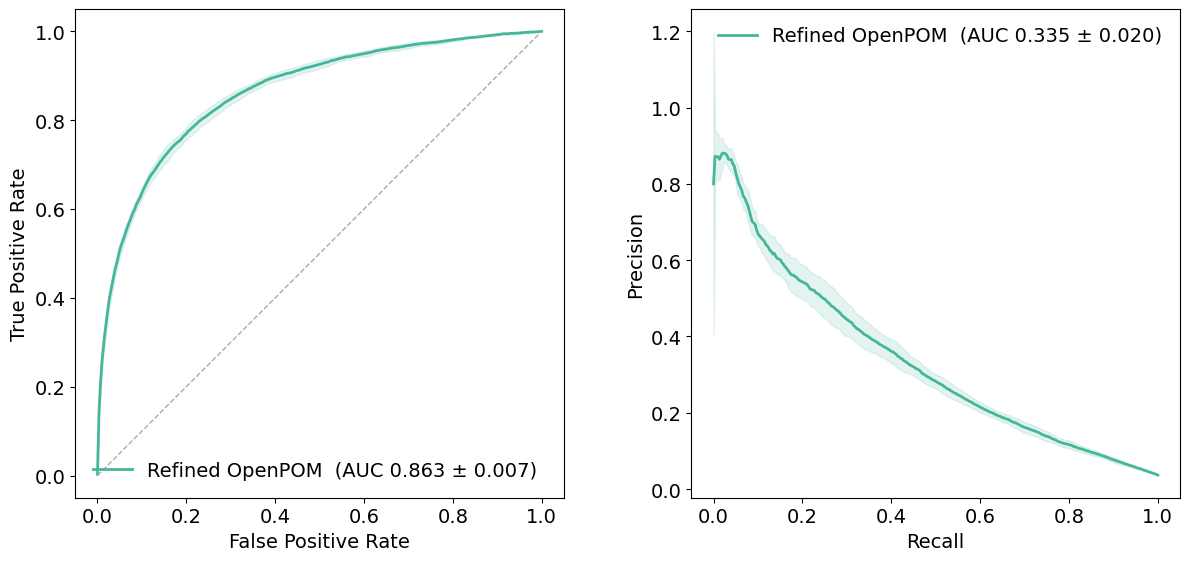

In [27]:
plot_cv_roc_pr_openpom(openpom_cv_results)